In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold,
    StratifiedKFold,
)
from sklearn.metrics import root_mean_squared_error
import numpy as np
from pipe import output_cross_val_results, TrainValidationTest

In [2]:
df_epi= pd.read_csv('data/epi_r_processed.csv', sep=',')
df_epi.info()

<class 'pandas.DataFrame'>
RangeIndex: 18251 entries, 0 to 18250
Columns: 347 entries, almond to rating
dtypes: float64(1), int64(346)
memory usage: 48.3 MB


In [3]:
y = df_epi['rating']
X = df_epi.drop(columns=['rating'])
y.shape, X.shape

((18251,), (18251, 346))

<Axes: ylabel='Frequency'>

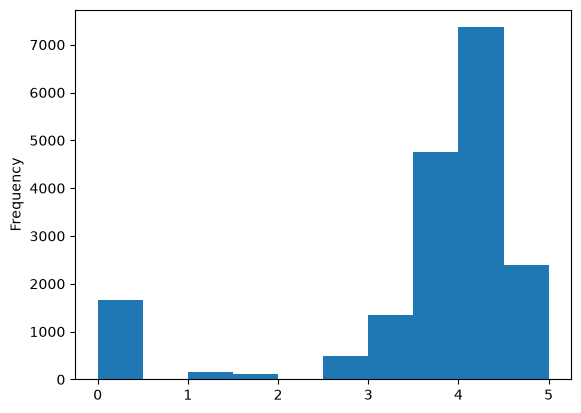

In [4]:
from pipe import TrainValidationTest

tvt = TrainValidationTest()
X_train, X_valid, X_test, y_train, y_valid, y_test = tvt.get_datasets(X, y)
y.plot.hist()

<Axes: xlabel='rating'>

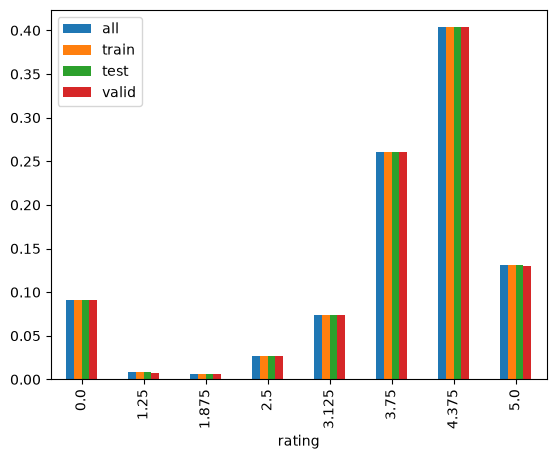

In [5]:
def norm_value_counts(vals):
    return vals.value_counts(normalize=True).sort_index()


pd.DataFrame(
    {
        "all": norm_value_counts(y),
        "train": norm_value_counts(y_train),
        "test": norm_value_counts(y_test),
        "valid": norm_value_counts(y_valid),
    }
).plot.bar()

In [6]:
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

### LinearRegression 

In [7]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](346,)","[ 0.13, 0.36,-0.16,..., 0.52, 0.02, 0.28]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](346,)","['almond','amaretto','anchovy',...,'yuca','zucchini','turkey']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.433
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,346
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(343)


In [8]:
cvs_log_reg = cross_val_score(lin_reg, X_train, y_train, scoring='neg_root_mean_squared_error', cv=cv_strategy)
output_cross_val_results(cvs_log_reg, lin_reg.__class__.__name__)

Cross-validation sore of mode LinearRegression
mean = 1.29, std=0.03


In [9]:
from sklearn.linear_model import Lasso

In [10]:
from sklearn.linear_model import LassoCV

# LassoCV автоматически переберет сетку alpha и выберет лучшую
lasso_cv = LassoCV(cv=5, random_state=42)
lasso_cv.fit(X_train, y_train)

print(f"Оптимальный alpha: {lasso_cv.alpha_}")

Оптимальный alpha: 0.0007703714008120958


In [11]:
lasso_clf = Lasso(alpha=lasso_cv.alpha_)
cvs_lasso = cross_val_score(
    lasso_clf, X_train, y_train, scoring="neg_root_mean_squared_error", cv=cv_strategy
)
output_cross_val_results(cvs_lasso, lasso_clf.__class__.__name__)

Cross-validation sore of mode Lasso
mean = 1.28, std=0.03


In [12]:
lasso_clf.fit(X_train, y_train)
lasso_coef = pd.DataFrame({'coef': np.abs(lasso_clf.coef_), 'name': lasso_clf.feature_names_in_})
lasso_coef.sort_values(by='coef', ascending=False).to_csv('data/lasso_coef.csv', index=False)

In [13]:
lasso_cols_importatant = lasso_coef[lasso_coef['coef'] != 0]['name']
lasso_cols_importatant

0          almond
1        amaretto
6         apricot
8         arugula
10      asparagus
          ...    
337    watermelon
338       whiskey
339    white wine
342        yogurt
345        turkey
Name: name, Length: 180, dtype: str

In [14]:
cvs_log_reg = cross_val_score(lin_reg, X_train[lasso_cols_importatant], y_train, scoring='neg_root_mean_squared_error', cv=cv_strategy)

In [15]:
from sklearn.ensemble import RandomForestRegressor

rf_clf = RandomForestRegressor(random_state=21, n_jobs=-1)
cvs_rf_clf = cross_val_score(
    rf_clf,
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=-1,
)
output_cross_val_results(cvs_rf_clf, rf_clf.__class__.__name__)

Cross-validation sore of mode RandomForestRegressor
mean = 1.39, std=0.04


In [ ]:
from sklearn.model_selection import GridSearchCV
from pipe import ModelSelectionRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import (
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    StackingRegressor,
)
cv = 2  # 5

lin_reg_param = {"fit_intercept": [True]}
lin_reg = LinearRegression()
lin_reg_cv = GridSearchCV(
    lin_reg,
    lin_reg_param,
    n_jobs=-1,
    cv=cv,
    scoring="neg_mean_squared_error",
)

ridge_param = {
    "alpha": [1000, 100, 10, 1, 0.1, 0.01, 0.001, 0.0001],
    "solver": ["svd", "cholesky", "lsqr", "sparse_cg", "sag", "saga"],
}
ridge = Ridge()

ridge_cv = GridSearchCV(
    ridge,
    ridge_param,
    n_jobs=-1,
    cv=cv,
    scoring="neg_mean_squared_error",
)
lasso_param = {
    "alpha": [1000, 100, 10, 1, 0.1, 0.01, 0.001, 0.0001],
}
lasso = Lasso(random_state=21)
lasso_cv = GridSearchCV(
    lasso,
    lasso_param,
    n_jobs=-1,
    cv=cv,
    scoring="neg_mean_squared_error",
)

rf = RandomForestRegressor(random_state=21, n_jobs=-1)
rf_grid = {
    "n_estimators": [400, 500, 750, 1000],  # Number of trees in the forest
    "max_depth": [None, 10, 20, 30, 40],  # Maximum depth of the trees
    "min_samples_split": [2, 5, 10],  # Minimum samples required to split a node
    "min_samples_leaf": [1, 2, 4],  # Minimum samples required at each leaf node
    "max_features": ["sqrt", "log2"],  # Number of features to consider at each split
}

# 4. Set up GridSearchCV with 5-fold cross-validation
rf_cv = GridSearchCV(
    estimator=rf,
    param_grid=rf_grid,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)


gbr = GradientBoostingRegressor(random_state=42)
gbr_params = {"n_estimators":[150, 200, 300], 
              "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
gbr_cv = GridSearchCV(
    estimator=gbr,
    param_grid=gbr_params,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)

hgbr = HistGradientBoostingRegressor(random_state=42)
hgbr_params = {
            "max_iter": [200, 300],
            "learning_rate": [0.05, 0.1, 0.2],
            "max_depth": [3, 5, None],
        }
hgbr_cv = GridSearchCV(
    estimator=hgbr,
    param_grid=hgbr_params,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)


In [27]:
params = [lin_reg_cv, ridge_cv, lasso_cv, rf_cv, gbr_cv, hgbr_cv]

ms_reg = ModelSelectionRegression(params)
ms_reg.choose(X_train, y_train, X_valid, y_valid)

Estimator: LinearRegression


100%|██████████| 1/1 [00:00<00:00,  1.49it/s]


Best params: {'fit_intercept': True}
Best training RMSE: 1.304
Validation set RMSE score for best params: 1.27

Estimator: Ridge


100%|██████████| 48/48 [01:04<00:00,  1.34s/it]


Best params: {'alpha': 10, 'solver': 'sparse_cg'}
Best training RMSE: 1.284
Validation set RMSE score for best params: 1.27

Estimator: Lasso


100%|██████████| 8/8 [00:01<00:00,  4.25it/s]


... (4 outputs left out)

Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}
Best training RMSE: 1.291
Validation set RMSE score for best params: 1.27

Estimator: HistGradientBoostingRegressor


100%|██████████| 18/18 [01:45<00:00,  5.87s/it]


Best params: {'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 200}
Best training RMSE: 1.286
Validation set RMSE score for best params: 1.26

Classifier with best validation set RMSE: GridSearchCV(cv=2,
             estimator=RandomForestRegressor(max_depth=40, max_features='log2',
                                             min_samples_leaf=4,
                                             min_samples_split=10,
                                             n_estimators=500, n_jobs=-1,
                                             random_state=21),
             n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30, 40],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [300, 400, 500]},
             scoring='neg_mean_squared_error')


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=21)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support f

In [28]:
pd.DataFrame(ms_reg.model_results).T.sort_values(by='valid_score', ascending=True)

,name,params,valid_score
3,"GridSearchCV(cv=2,\n estimator=Ran...","{'max_depth': None, 'max_features': 'log2', 'm...",1.273658
1,"GridSearchCV(cv=2, estimator=Ridge(alpha=0.000...","{'alpha': 10, 'solver': 'sparse_cg'}",1.284157
2,"GridSearchCV(cv=2, estimator=Lasso(alpha=0.000...",{'alpha': 0.001},1.284583
5,"GridSearchCV(cv=2,\n estimator=His...","{'learning_rate': 0.1, 'max_depth': 3, 'max_it...",1.285928
4,"GridSearchCV(cv=2,\n estimator=Gra...","{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",1.29096
0,"GridSearchCV(cv=2, estimator=LinearRegression(...",{'fit_intercept': True},1.30418


In [29]:
assert 1 == 0

AssertionError: 